In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
from sklearn.datasets import load_iris

In [5]:
iris = load_iris()

df = pd.DataFrame(data=iris.data, columns=iris.feature_names)

In [6]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [7]:
df['target'] = iris.target
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))

In [8]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


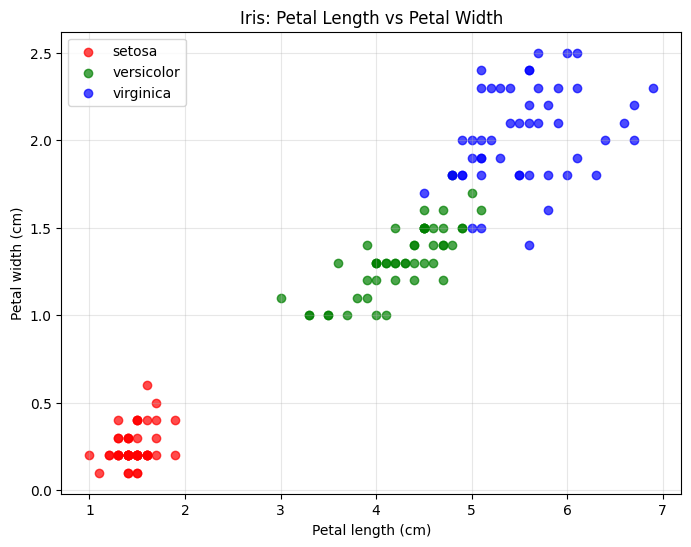

In [9]:
colors = {'setosa': 'red', 'versicolor': 'green', 'virginica': 'blue'}

plt.figure(figsize=(8, 6))
for species, group in df.groupby('species'):
    plt.scatter(group['petal length (cm)'], group['petal width (cm)'],
                label=species, color=colors[species], alpha=0.7)

plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title('Iris: Petal Length vs Petal Width')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
X = df.drop(columns='species')
y = df['species']

In [12]:
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [13]:
y.head()

,species
0,setosa
1,setosa
2,setosa
3,setosa
4,setosa


In [14]:
from sklearn.preprocessing import LabelEncoder

In [15]:
le = LabelEncoder()
y = le.fit_transform(df['species'])

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=45)

In [17]:
from sklearn.linear_model import LogisticRegression

In [18]:
model = LogisticRegression()

In [19]:
model.fit(X_train,y_train)

LogisticRegression()

In [20]:
y_pred = model.predict(X=X_test)

In [21]:
from sklearn.metrics import r2_score,mean_squared_error,accuracy_score

In [22]:
r2_Score_ = r2_score(y_pred=y_pred,y_true=y_test)
print("R² :", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred)**0.5)


R² : 1.0
RMSE: 0.0


In [23]:

print("Accuracy Score :", accuracy_score(y_test,y_pred))

Accuracy Score : 1.0


In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [26]:
cm = confusion_matrix(y_pred=y_pred,y_true=y_test)
cm

array([[17,  0,  0],
       [ 0, 13,  0],
       [ 0,  0, 15]])

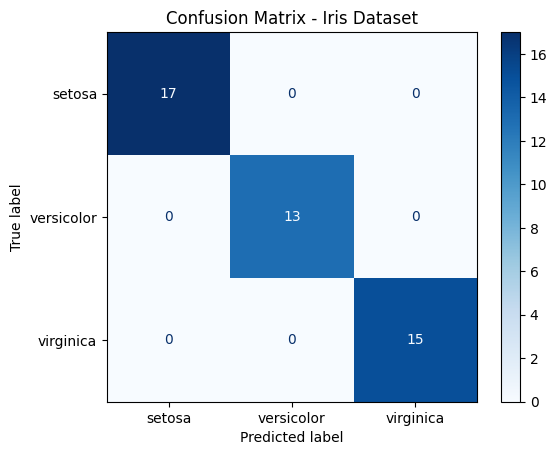

In [27]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Iris Dataset")
plt.show()